**Write the names of all group members (max. 5 members)**:

Giacomo Maggiore

Ugo Buzzacchino

Konstantin Krstevski

Julius Voss

Konstantinos Zisis


When submitting your work, please follow closely the template below.

Implement the models from scratch using PyTorch (you may adapt `demo.ipynb`) or TensorFlow. Do not use third-party repositories containing ready-made deep hedging implementations. One submission per team is enough.

Make sure all requested results are visible in the executed notebook. A concise **Project Report** is required at the end of the notebook.

In [1]:
# Import necessary libraries
#%pip install torch

import numpy as np
import math
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.distributions import Normal
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm

# Exercise 1

### Question 1.a

Use Itô’s formula to check that $S_t=s_0\exp(\sigma W_t-\frac12\sigma^2t)$ solves the Black–Scholes SDE with $r=0$. 

Let $f(t,w) = s_0 e^{\sigma w - \frac{1}{2}\sigma^2 t}$, so $S_t = f(t, W_t)$. The partial derivatives are

$$
\partial_t f = -\tfrac{1}{2}\sigma^2 f, \qquad \partial_w f = \sigma f, \qquad \partial_{ww} f = \sigma^2 f.
$$

By Itô's formula,

$$
dS_t = \Big(\partial_t f + \tfrac{1}{2}\partial_{ww} f\Big)dt + \partial_w f\, dW_t
= \Big(-\tfrac{1}{2}\sigma^2 + \tfrac{1}{2}\sigma^2\Big) S_t\, dt + \sigma S_t\, dW_t
= \sigma S_t\, dW_t .
$$

Since $W_0 = 0$, we have $S_0 = s_0$. Hence $S_t$ solves SDE (1) with $r = 0$. 

### Question 1.b - Generate dataset

In [2]:
# Generate 100,000 training paths and 10,000 independent test paths.
# Parameters: N=30, s0=1, T=1/4 year, sigma=0.35, r=0.
# Use the exact geometric Brownian motion update specified in Problem 1(b).
# Each path contains N+1=31 prices, including S0 and ST.

K, N, s0, T, sigma, r = 1.0, 30, 1.0, 0.25, 0.35, 0.0
dt = T / N

def simulate_gbm(m, rng):
    Z = rng.standard_normal((m, N))
    log_incr = -0.5 * sigma**2 * dt + sigma * np.sqrt(dt) * Z
    log_S = np.concatenate([np.zeros((m, 1)), np.cumsum(log_incr, axis=1)], axis=1)
    return s0 * np.exp(log_S)  

rng = np.random.default_rng(0)
# Generate the training set
S_train = simulate_gbm(100_000, rng)
# Generate the test set
S_test = simulate_gbm(10_000, rng)
print(S_train.shape, S_test.shape) 

(100000, 31) (10000, 31)


### Question 1.c - Model implementation

In [3]:
# Implement the deep hedging model from scratch.
# You may use and edit the code shown in demo.ipynb.
torch.manual_seed(1)

N = 30     # number of trading dates
nh1 = 32   # neurons in first hidden layer (based on the example in the demo)
nh2 = 32   # neurons in second hidden layer

def make_network():
    return nn.Sequential(nn.Linear(1, nh1), #first layer
                         nn.Tanh(), #activation function (hyperbolic tangent)
                         nn.Linear(nh1, nh2), #second layer
                         nn.Tanh(), #activation function (hyperbolic tangent)
                         nn.Linear(nh2, 1)) #output layer

# Create 30 separate networks H_0,...,H_29, each with its own parameters.
H = nn.ModuleList([make_network() for _ in range(N)])
# Each network takes the current stock price as input and returns the shares to hold.
# Do not use future prices as inputs to the trading decision.

### Question 1.d - Model training

p = C(0, s0) = 0.069726


100%|██████████| 100/100 [01:58<00:00,  1.19s/it, loss=0.000114]


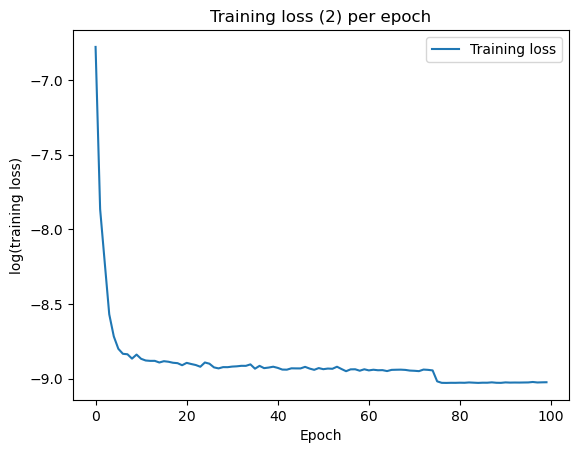

In [4]:
# Implement the hedge_positions function that takes a batch of paths S and returns the corresponding batch of hedging positions.
# H[j] neural networks for time j 
# S[:, j:j+1] selects the stock price at time j for every path, preserving the shape (B, 1).
# torch.cat combined N output cols
def hedge_positions(S):
    return torch.cat([H[j](S[:, j:j+1]) for j in range(N)], dim=1)
# Implement the call payoff with strike K=1 and maturity T=1/4 year.
def payoff(S_T, K=K):
    return torch.clamp(S_T - K, min=0.0)

# Implement the Black-Scholes call-price formula (3).
def bs_call_price(t, s, K=K, T=T, sigma=sigma, r=r):
    s = torch.as_tensor(s, dtype=torch.float32)
    tau = T - t
    d_plus = (torch.log(s / K) + (r + 0.5 * sigma**2) * tau) / (sigma * math.sqrt(tau))
    d_minus = d_plus - sigma * math.sqrt(tau)
    Phi = Normal(0.0, 1.0).cdf
    return Phi(d_plus) * s - Phi(d_minus) * K * math.exp(-r * tau)
# Compute and fix the initial premium p=C(0,s0); p is not trained.
p = bs_call_price(0.0, s0).item()
print(f"p = C(0, s0) = {p:.6f}")

# Train all 30 networks jointly by minimizing equation (2) on the training set.

# Define training hyperparameters
n_epochs = 100
lr = 1e-2
batch_size = 1000
milestones = [75]

# Instantiate an optimizer (only the network parameters are trained; p is fixed)
optimizer = torch.optim.Adam(H.parameters(), lr=lr)

# Instantiate a scheduler to decrease the learning rate during training according to a pre-defined rule
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=milestones, gamma=0.1)

# Create a batch loader from the training paths
dataset = TensorDataset(torch.as_tensor(S_train, dtype=torch.float32))
loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

# Training

losses = torch.empty(n_epochs)
training_loop = tqdm(range(n_epochs))
for epoch in training_loop:
    epoch_loss = 0.0

    # At each epoch iterate over batches
    for S, in loader:
        # compute training loss (2) on batch
        dS = S[:, 1:] - S[:, :-1]
        pnl = p + torch.sum(hedge_positions(S) * dS, dim=1) - payoff(S[:, -1])
        loss = torch.mean(pnl**2)
        # compute gradient of training loss wrt parameters
        loss.backward()
        # do one gradient step
        optimizer.step()
        # reset the gradients
        optimizer.zero_grad()
        # accumulate a path-weighted epoch average
        epoch_loss += loss.item() * S.shape[0]

    # Print loss in the progression bar
    training_loop.set_postfix(loss = loss.item())

    # decrease learning rate according to scheduler's settings
    scheduler.step()

    # save the average training loss of the epoch for plotting
    losses[epoch] = epoch_loss / len(dataset)

plt.plot(torch.log(losses), label='Training loss')
plt.xlabel("Epoch")
plt.ylabel("log(training loss)")
plt.title("Training loss (2) per epoch")
plt.legend()
plt.show()

### Question 1.e - Model evaluation

Deep hedge P&L on test set: mean = 8.92e-06, std = 0.01115


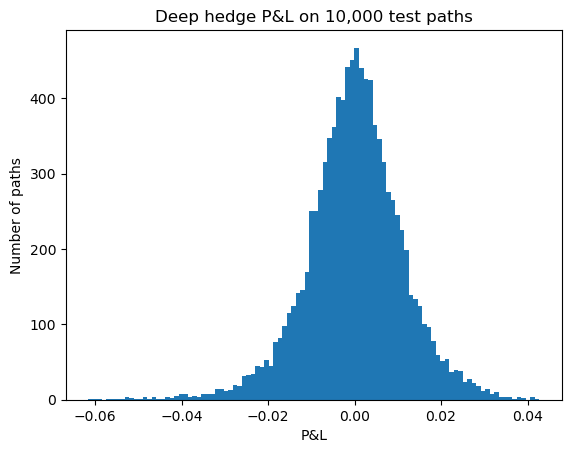

In [5]:
# Evaluate the trained hedge on the 10,000 independent test paths.
# Compute P&L = p + sum_j H_j(S_tj)*(S_tj+1-S_tj) - g(ST).
S_test = torch.as_tensor(S_test, dtype=torch.float32)

# P&L = p + sum_j H_j(S_tj) * (S_tj+1 - S_tj) - g(S_T), with trained networks frozen
with torch.no_grad():
    dS_test = S_test[:, 1:] - S_test[:, :-1]
    pnl_nn = p + torch.sum(hedge_positions(S_test) * dS_test, dim=1) - payoff(S_test[:, -1])

print(f"Deep hedge P&L on test set: mean = {pnl_nn.mean().item():.2e}, std = {pnl_nn.std().item():.5f}")


# Plot its histogram and print the empirical mean and standard deviation.
plt.hist(pnl_nn.numpy(), bins=100)
plt.xlabel("P&L")
plt.ylabel("Number of paths")
plt.title("Deep hedge P&L on 10,000 test paths")
plt.show()

### Question 1.f(i) - Compute analytical solution

Show a **step-by-step** derivation of the analytical hedging strategy:

With $\tau = T - t$, $r = 0$, $\varphi = \Phi'$ the standard normal density, and
$C(t,s) = s\,\Phi(d_+) - K\,\Phi(d_-)$, where $d_+ = \frac{\log(s/K) + \frac12\sigma^2\tau}{\sigma\sqrt{\tau}}$ and $d_- = d_+ - \sigma\sqrt{\tau}$:

\begin{align*}
H^{\text{BS}}_t(s) & = \frac{\partial C(t, s)}{\partial s} \\
& = \frac{\partial}{\partial s}\big[s\,\Phi(d_+)\big] - K\,\frac{\partial}{\partial s}\Phi(d_-) \\
& = \Phi(d_+) + s\,\varphi(d_+)\,\frac{\partial d_+}{\partial s} - K\,\varphi(d_-)\,\frac{\partial d_-}{\partial s} \\
& = \Phi(d_+) + \frac{1}{s\,\sigma\sqrt{\tau}}\Big(s\,\varphi(d_+) - K\,\varphi(d_-)\Big)
&& \text{(since } \tfrac{\partial d_+}{\partial s} = \tfrac{\partial d_-}{\partial s} = \tfrac{1}{s\,\sigma\sqrt{\tau}}\text{)} \\
& = \Phi(d_+)
&& \text{(since } K\,\varphi(d_-) = s\,\varphi(d_+)\text{, shown below)}
\end{align*}

The last step uses $d_- = d_+ - \sigma\sqrt{\tau}$:

\begin{align*}
\varphi(d_-) & = \frac{1}{\sqrt{2\pi}}\, e^{-\frac12 (d_+ - \sigma\sqrt{\tau})^2}
= \varphi(d_+)\, e^{\,d_+\sigma\sqrt{\tau} - \frac12\sigma^2\tau}
= \varphi(d_+)\, e^{\,\log(s/K)}
= \varphi(d_+)\,\frac{s}{K}.
\end{align*}

Hence
$$
\boxed{\,H^{\text{BS}}_t(s) = \Phi(d_+) = \Phi\!\left(\frac{\log(s/K) + \frac12\sigma^2 (T-t)}{\sigma\sqrt{T-t}}\right)\,}
$$

No points for solutions without explicit derivation.

### Question 1.f(ii) - P&L comparison with the analytical hedge

Deep hedge P&L: mean = 8.92e-06, std = 0.01115
BS delta P&L:   mean = 5.85e-06, std = 0.01105
Std of path-wise difference (deep hedge - BS delta) = 0.00131


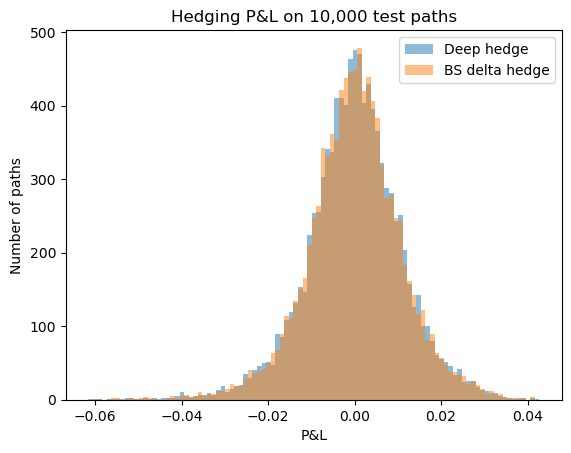

In [6]:
# Implement the formula you found
def bs_delta(t, s, K=K, T=T, sigma=sigma):
    # H^BS_t(s) = Phi(d_+), with r = 0
    tau = T - t
    d_plus = (torch.log(s / K) + 0.5 * sigma**2 * tau) / (sigma * torch.sqrt(tau))
    return Normal(0.0, 1.0).cdf(d_plus)

# Rebalance at t_0,...,t_29 using the same test paths, premium and payoff as in 1.e.
t_grid = torch.arange(N) * T / N                       # t_0, ..., t_29
positions_bs = bs_delta(t_grid, S_test[:, :-1])        # (10000, 30), column j = H^BS_{t_j}(S_{t_j})

# Compute P&L using the same sign convention as in 1.e.
pnl_bs = p + torch.sum(positions_bs * dS_test, dim=1) - payoff(S_test[:, -1])

# Plot histograms of both P&L distributions and print their means and standard deviations.
print(f"Deep hedge P&L: mean = {pnl_nn.mean().item():.2e}, std = {pnl_nn.std().item():.5f}")
print(f"BS delta P&L:   mean = {pnl_bs.mean().item():.2e}, std = {pnl_bs.std().item():.5f}")
# Path-wise difference: small if both strategies give nearly the same P&L on every path
print(f"Std of path-wise difference (deep hedge - BS delta) = {(pnl_nn - pnl_bs).std().item():.5f}")

bins = torch.linspace(min(pnl_nn.min(), pnl_bs.min()).item(), max(pnl_nn.max(), pnl_bs.max()).item(), 100).numpy()
plt.hist(pnl_nn.numpy(), bins=bins, alpha=0.5, label="Deep hedge")
plt.hist(pnl_bs.numpy(), bins=bins, alpha=0.5, label="BS delta hedge")
plt.xlabel("P&L")
plt.ylabel("Number of paths")
plt.title("Hedging P&L on 10,000 test paths")
plt.legend()
plt.show()

How does your deep hedging model compare with the analytical solution? If it's worse, you must improve its performance. A few questions for you to consider...

Have you trained your deep hedging model well?
- Are the losses centered on zero? ($10^{-5} \approx 0$)
- Is their standard deviation comparable with that of the analytical solution?

How can you improve performance?
- train for more epochs
- try a different learning rate
- change the networks' architectures (first try more hidden neurons, then try more hidden layers)
- try different batch sizes
- use a learning rate scheduler (see https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)
- try a different activation function (e.g. $\tanh$)
- implement regularization (use the `weight_decay` argument in the optimizer)
- implement batch-normalization (see https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html)
- experiment with different optimizers
- ask in the forum

**Comparison with the analytical hedge**

- Both P&L distributions are centered on zero: the means are $8.9 \cdot 10^{-6}$ (deep hedge) and $5.9 \cdot 10^{-6}$ (BS delta), i.e. $\approx 0$.
- Their standard deviations are comparable: 0.01115 (deep hedge) vs. 0.01105 (BS delta), less than 1% apart, and the two histograms almost coincide.
- The two strategies give nearly the same P&L on every path: the path-wise difference has standard deviation 0.00131, about 8 times smaller than the P&L standard deviation.
- So the deep hedge is well trained. The remaining spread of about 0.011 is also present for the exact delta hedge: it comes from rebalancing only at $N = 30$ dates, not from the networks.
- Setup: two hidden layers of 32 neurons with $\tanh$, and the training setup of `demo.ipynb` (Adam with learning rate $10^{-2}$, batch size 1000, 100 epochs, learning rate divided by 10 after epoch 75).

### Question 1.g - Learned strategy comparison with analytical solution

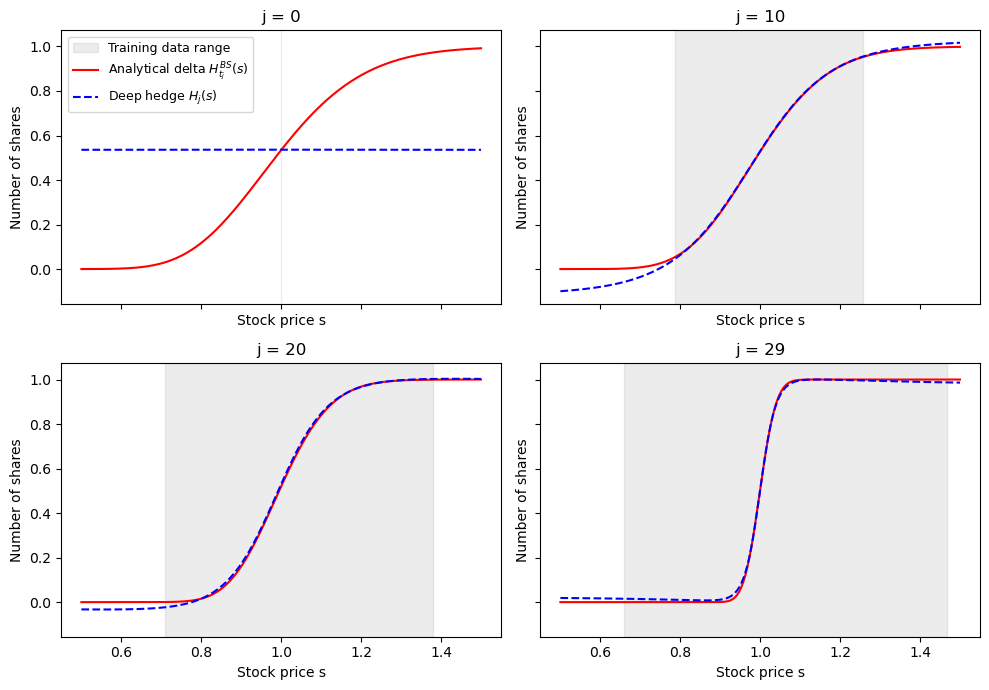

In [7]:
# Compare the hedge functions at j=0,10,20,29.
# Make a grid of stock prices s in [0.5,1.5].
# Create four plots or panels, one per selected date.
# In each panel, overlay H_j(s) and the analytical delta evaluated on the same price grid.
# Label the date, both strategies, and axes (stock price and number of shares).

s_grid = torch.linspace(0.5, 1.5, 200).unsqueeze(1)   # (200, 1), input shape for the networks
S_train = torch.as_tensor(S_train, dtype=torch.float32)
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for ax, j in zip(axes.flat, [0, 10, 20, 29]):
    t_j = torch.tensor(j * T / N)
    with torch.no_grad():
        h_nn = H[j](s_grid).squeeze(1)
    h_bs = bs_delta(t_j, s_grid.squeeze(1))

    # Range of training prices at t_j (1st-99th percentile): where H_j actually saw data
    lo, hi = torch.quantile(S_train[:, j], torch.tensor([0.01, 0.99]))
    ax.axvspan(lo.item(), hi.item(), color="gray", alpha=0.15, label="Training data range")

    ax.plot(s_grid.squeeze(1), h_bs, "r-", label="Analytical delta $H^{BS}_{t_j}(s)$")
    ax.plot(s_grid.squeeze(1), h_nn, "b--", label="Deep hedge $H_j(s)$")
    ax.set_title(f"j = {j}")
    ax.set_xlabel("Stock price s")
    ax.set_ylabel("Number of shares")

axes[0, 0].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("output/1g_hedge_comparison.png", dpi=150)
plt.show()

- For what times $t_j$ are the two functions most similar?

The functions are most similar at the later dates ($j = 20, 29$). At $j = 0$ they agree only near $s = 1$.

- Why?

Each network $H_j$ is trained only on the prices $S_{t_j}$ observed in the training set, so it can only learn delta where it sees data. At $t_0$ every path starts at $s_0 = 1$, so $H_0$ sees a single input value: it is accurate at $s = 1$ and unconstrained elsewhere on $[0.5, 1.5]$. As time passes, the paths spread out, since $\operatorname{Var}(\log S_{t_j}) = \sigma^2 t_j$ grows linearly in $t_j$. The later networks therefore see prices across most of $[0.5, 1.5]$ and match delta over a much wider range (the shaded data range in the plots). Outside the data range, a network extrapolates, and nothing in the loss forces it to agree with delta there.

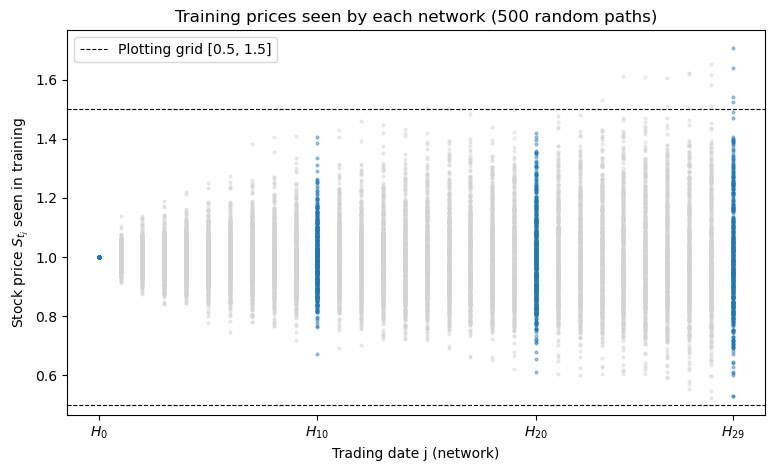

H_0 : 98% of training prices in [1.000, 1.000]
H_10: 98% of training prices in [0.787, 1.258]
H_20: 98% of training prices in [0.710, 1.379]
H_29: 98% of training prices in [0.660, 1.467]


In [8]:
# Supporting plot for 1.g: what each network H_j has seen during training

S_train = torch.as_tensor(S_train, dtype=torch.float32)
n_show = 500                                           
# fixed subset of paths (own generator, so the global torch seed is not affected)
idx = torch.randperm(S_train.shape[0], generator=torch.Generator().manual_seed(0))[:n_show]
selected = [0, 10, 20, 29]

plt.figure(figsize=(9, 5))
for j in range(N):
    color = "tab:blue" if j in selected else "lightgray"
    plt.scatter(torch.full((n_show,), j), S_train[idx, j], s=4, color=color, alpha=0.4)

# Plotting grid used in 1.g
plt.axhline(0.5, color="black", linestyle="--", linewidth=0.8, label="Plotting grid [0.5, 1.5]")
plt.axhline(1.5, color="black", linestyle="--", linewidth=0.8)

plt.xticks(selected, [f"$H_{{{j}}}$" for j in selected])
plt.xlabel("Trading date j (network)")
plt.ylabel("Stock price $S_{t_j}$ seen in training")
plt.title(f"Training prices seen by each network ({n_show} random paths)")
plt.legend(loc="upper left")
plt.savefig("output/1g_training_data_seen.png", dpi=150)
plt.show()

# Print the observed price range for the selected networks (all 100,000 paths)
for j in selected:
    lo, hi = torch.quantile(S_train[:, j], torch.tensor([0.01, 0.99]))
    print(f"H_{j:<2}: 98% of training prices in [{lo:.3f}, {hi:.3f}]")

# Exercise 2

### Question 2.a - Generate dataset

In [9]:
# Generate 100,000 training paths and 10,000 independent test paths of (S,V).
# Parameters: N=30, s0=1, T=1/4 year, rho=-0.3, a=4, b=0.5, v0=0.5, sigma=1.
# Each stock and variance path contains N+1=31 values.

N = 30
T = 0.25
rho = -0.3
dt = T /N
s0 = 1
v0 = 0.5

a = 4
b = 0.5
# sigma=1 is called sigma_v, so that sigma=0.35 of Exercise 1 is not overwritten
sigma_v = 1

# (i) Write a function to simulate V using the exact noncentral chi-square transitions.

# m rows: one for each path 
# N + 1 cols: one for each time step (including t=0)
# rng.noncentral_chisquare samples the same distribution as scipy.stats.ncx2

def simulate_variance(m, rng):
    V = np.empty((m, N + 1))
    V[:, 0] = v0

    decay = np.exp(-a * dt)
    c = sigma_v**2 / (4 * a) * (1 - decay)
    degrees_freedom = 4 * a * b / sigma_v**2

    for j in range(N):
        lambda_j = decay * V[:, j] / c
        V[:, j + 1] = c * rng.noncentral_chisquare(degrees_freedom, lambda_j)

    return V

# (ii) Write a function to simulate S using the supplied simplified Broadie-Kaya update.

def simulate_stock_broadie_kaya(V, rng):
    m = V.shape[0]
    
    # same shape as V, filled column by column below
    S = np.empty_like(V)
    S[:, 0] = s0

    for j in range(N):
        # independent standard normal random variables Z_j for each path
        Z = rng.standard_normal(m)
        log_return = (
            rho / sigma_v * (V[:, j + 1] - V[:, j] - a * b * dt)
            + (a * rho / sigma_v - 0.5) * V[:, j] * dt
            + np.sqrt((1 - rho**2) * V[:, j] * dt) * Z
        )
        S[:, j + 1] = S[:, j] * np.exp(log_return)

    return S

# Own seed for Exercise 2, so the data does not depend on the cells run before.
rng = np.random.default_rng(1)

V_heston_train = simulate_variance(100_000, rng)
S_heston_train = simulate_stock_broadie_kaya(V_heston_train, rng)

# Generate independent test paths for later evaluation.
V_heston_test = simulate_variance(10_000, rng)
S_heston_test = simulate_stock_broadie_kaya(V_heston_test, rng)

print(S_heston_train.shape, V_heston_train.shape, S_heston_test.shape, V_heston_test.shape)

# Sanity checks: V stays positive, and S should be a martingale, so E[S_T] = s0 = 1.
print(f"min V (train) = {V_heston_train.min():.4f}")
print(f"mean S_T: train = {S_heston_train[:, -1].mean():.4f}, test = {S_heston_test[:, -1].mean():.4f}")

(100000, 31) (100000, 31) (10000, 31) (10000, 31)
min V (train) = 0.0059
mean S_T: train = 0.9992, test = 0.9989


### Question 2.b - Model implementation

In [10]:
# Implement the deep hedging model for a generic AVaR level alpha.
# Create 30 separate networks, each taking (current stock price, current variance)
# as input and returning one stock holding.
# Implement the AVaR objective in equation (6), with a trainable scalar threshold w.

# 30 separate networks H_0, ..., H_29, each with its own parameters

# networks
def make_heston_network():
    return nn.Sequential(
        nn.Linear(2, 32), nn.Tanh(),
        nn.Linear(32, 32), nn.Tanh(),
        nn.Linear(32, 1),
    )

# Each network takes the current stock price and variance and returns the shares to hold.

def hedged_loss(S, V, networks):
    # calculate stock holdings for each time step using the corresponding network
    positions = torch.cat([
        
        # networks[j](...) returns one stock holding per path
        networks[j](torch.stack((S[:, j], V[:, j]), dim=1))
        for j in range(N)
    ], dim=1)

    # trading gains 
    trading_gain = (positions * (S[:, 1:] - S[:, :-1])).sum(dim=1)
    
    # path loss X = g(ST) - trading_gain (the premium p is not included)
    return torch.clamp(S[:, -1] - K, min=0.0) - trading_gain

def avar_objective(S, V, networks, w, alpha):
    if not 0 <= alpha < 1:
        raise ValueError("alpha must satisfy 0 <= alpha < 1")

    path_loss = hedged_loss(S, V, networks)

    # AVar objective: w + (1/(1-alpha)) * E[max(path_loss - w, 0)]
    return w + torch.relu(path_loss - w).mean() / (1 - alpha)



### Question 2.c - Model training

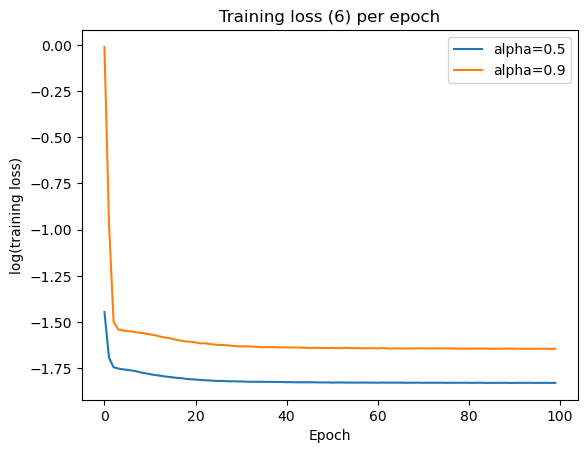

Trained thresholds w for each alpha:
0.13490614295005798
0.17597179114818573


In [11]:
# Train two separate deep hedging models for alpha=0.5 and alpha=0.9.
# Use the call option with strike K=1 and maturity T=1/4 year.
# Minimize equation (6), jointly optimizing all network parameters and scalar w.
# Each model has its own networks and one threshold w shared across its paths.
# Include w in the optimizer; do not fix a Black-Scholes premium in this objective.

# Set training choices and a seed for reproducibility.
# Same batch size and epochs as in Exercise 1; Adam with its default lr=1e-3 and no scheduler
# (the loss curves below are flat in the last epochs).
torch.manual_seed(2)
n_epochs = 100
learning_rate = 0.001

# Pair each stock path with its corresponding variance path.
train_dataset = TensorDataset(
    torch.as_tensor(S_heston_train, dtype=torch.float32),
    torch.as_tensor(V_heston_train, dtype=torch.float32),)

train_loader = DataLoader(train_dataset, batch_size=1000, shuffle=True)

# Keep both trained models for the test-set comparison.
models = {}

# consider median and 90th percentile AVaR levels
for alpha in [0.5, 0.9]:
    # Create a new set of networks and a new threshold w for each alpha.
    networks = nn.ModuleList([make_heston_network() for _ in range(N)])
    
    # Create one trainable threshold shared across all paths.
    w = nn.Parameter(torch.tensor(0.0))
    
    # Train the network parameters and threshold together.
    # w chosen as a parameter to be optimized, not a fixed value (adam)
    optimizer = torch.optim.Adam([*networks.parameters(), w], lr=learning_rate)
    
    losses = torch.empty(n_epochs)
    for epoch in range(n_epochs):
        total_loss = 0.0

        for S_batch, V_batch in train_loader:
            # Clear gradients from the previous batch.
            optimizer.zero_grad()

            # Calculate equation (6) for this batch.
            loss = avar_objective(S_batch, V_batch, networks, w, alpha)

            # Calculate gradients and update networks and w.
            loss.backward()
            optimizer.step()

            # Accumulate a path-weighted epoch average.
            total_loss += loss.item() * S_batch.shape[0]

        # save the average training loss of the epoch for plotting
        losses[epoch] = total_loss / len(train_dataset)

    # Save this model before creating the next one.
    models[alpha] = {"networks": networks, "w": w, "losses": losses}
    

# Training loss per epoch for both models
for alpha in [0.5, 0.9]:
    plt.plot(torch.log(models[alpha]["losses"]), label=f"alpha={alpha}")
plt.xlabel("Epoch")
plt.ylabel("log(training loss)")
plt.title("Training loss (6) per epoch")
plt.legend()
plt.show()

# after training, each model has its own networks and threshold w, which can be used for evaluation on the test set.
print("Trained thresholds w for each alpha:")
print(models[0.5]["w"].item())
print(models[0.9]["w"].item())

### Question 2.d - Price comparison

In [12]:
# Freeze each trained model and its threshold w.
# Evaluate equation (6) on the same 10,000 test paths to estimate each price p.
# Print p for alpha=0.5 and alpha=0.9.
# Explain which price is higher and why.

# Convert the same test paths to tensors for both models.
S_test_tensor = torch.as_tensor(S_heston_test, dtype=torch.float32)
V_test_tensor = torch.as_tensor(V_heston_test, dtype=torch.float32)

prices = {}

for alpha in [0.5, 0.9]:
    # Retrieve the networks and threshold trained for this alpha.
    networks = models[alpha]["networks"]
    w = models[alpha]["w"]

    # Freeze the networks and threshold for evaluation.
    networks.eval()
    networks.requires_grad_(False)
    w.requires_grad_(False)

    # Evaluate equation (6) without calculating gradients.
    with torch.no_grad():
        price = avar_objective(
            S_test_tensor, V_test_tensor, networks, w, alpha)
        X = hedged_loss(S_test_tensor, V_test_tensor, networks)

    # Store and print the estimated risk-based premium.
    prices[alpha] = price.item()
    print(f"alpha={alpha}: p={prices[alpha]:.6f}")
    # The optimal w in (6) is the alpha-quantile (VaR) of the hedged loss X: compare with the test quantile.
    print(f"           trained w={w.item():.4f}, {alpha}-quantile of X on test set={torch.quantile(X, alpha).item():.4f}")


alpha=0.5: p=0.160646
           trained w=0.1349, 0.5-quantile of X on test set=0.1353


alpha=0.9: p=0.193714
           trained w=0.1760, 0.9-quantile of X on test set=0.1763


The price for $\alpha=0.9$ is higher: 0.1937 versus 0.1606 for $\alpha=0.5$.

AVaR at $\alpha=0.9$ focuses on the worst 10% of hedging losses, whereas $\alpha=0.5$ considers the worst 50%. Focusing on more severe losses leads to a higher risk-based premium.

More precisely, $\text{AVaR}_\alpha(X) = \frac{1}{1-\alpha}\int_\alpha^1 q_u(X)\,du$ is the average of the quantiles $q_u(X)$ for $u \in [\alpha, 1]$. Since $u \mapsto q_u(X)$ is non-decreasing, this average is non-decreasing in $\alpha$, so $\text{AVaR}_{0.9}(X) \ge \text{AVaR}_{0.5}(X)$ for every strategy $H$. Taking the infimum over $H$ in (5) keeps this order, hence $p_{0.9} \ge p_{0.5}$.

The trained thresholds are consistent with this: in the variational formula the optimal $w$ is the $\alpha$-quantile (VaR) of the hedged loss $X$, and indeed $w = 0.1349$ vs. $q_{0.5}(X) = 0.1353$ and $w = 0.1760$ vs. $q_{0.9}(X) = 0.1763$ on the test set.

### Question 2.e - P&L comparison

alpha=0.5: mean=0.022935, std=0.031208


alpha=0.9: mean=0.055967, std=0.032998


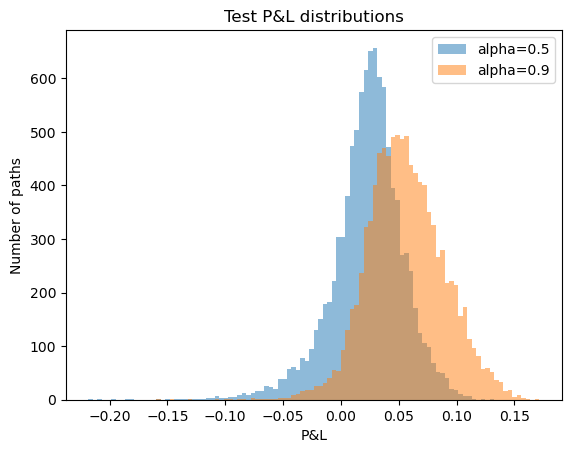

In [13]:
# Compute test P&L for alpha=0.5 and alpha=0.9.
# Use the same test paths for both models.
# Plot both P&L histograms with comparable axes and binning.
# Print the empirical mean and standard deviation for each distribution.

# Calculate call payoffs on the shared test paths.
payoff_test = torch.clamp(S_test_tensor[:, -1] - K, min=0.0)

pnl = {}

with torch.no_grad():
    for alpha in [0.5, 0.9]:
        networks = models[alpha]["networks"]

        # P&L = premium received + trading gains - option payoff = p - X
        pnl[alpha] = prices[alpha] - hedged_loss(S_test_tensor, V_test_tensor, networks)

        print(
            f"alpha={alpha}: "
            f"mean={pnl[alpha].mean().item():.6f}, "
            f"std={pnl[alpha].std().item():.6f}"
        )

# Use identical bins for both distributions.
all_pnl = torch.cat([pnl[0.5], pnl[0.9]]).cpu().numpy()
bins = np.histogram_bin_edges(all_pnl, bins=100)

for alpha in [0.5, 0.9]:
    plt.hist(
        pnl[alpha].cpu().numpy(),
        bins=bins,
        alpha=0.5,
        label=f"alpha={alpha}",
    )

plt.xlabel("P&L")
plt.ylabel("Number of paths")
plt.title("Test P&L distributions")
plt.legend()
plt.show()

In [14]:
# check: mean P&L = (p - E[payoff]) + E[trading gain].
# P&L - p is the hedging result without the premium, so its quantiles compare the two hedges.
print(f"Average payoff: {payoff_test.mean().item():.6f}")

for alpha in [0.5, 0.9]:
    trading_gain = pnl[alpha] - prices[alpha] + payoff_test
    std_error = trading_gain.std().item() / math.sqrt(len(trading_gain))
    q01, q05 = torch.quantile(pnl[alpha] - prices[alpha], torch.tensor([0.01, 0.05]))
    print(f"alpha={alpha}: p - E[payoff] = {prices[alpha] - payoff_test.mean().item():.6f}, "
          f"mean trading gain = {trading_gain.mean().item():.6f} (std. error {std_error:.6f}), "
          f"1% / 5% quantiles of P&L - p = {q01:.4f} / {q05:.4f}")

print(f"Price difference = {prices[0.9] - prices[0.5]:.6f}, "
      f"mean P&L difference = {(pnl[0.9].mean() - pnl[0.5].mean()).item():.6f}")

Average payoff: 0.137589
alpha=0.5: p - E[payoff] = 0.023057, mean trading gain = -0.000122 (std. error 0.002389), 1% / 5% quantiles of P&L - p = -0.2320 / -0.1928
alpha=0.9: p - E[payoff] = 0.056125, mean trading gain = -0.000157 (std. error 0.002383), 1% / 5% quantiles of P&L - p = -0.2172 / -0.1880
Price difference = 0.033068, mean P&L difference = 0.033032


Test P&L: mean 0.0229 and standard deviation 0.0312 for $\alpha=0.5$; mean 0.0560 and standard deviation 0.0330 for $\alpha=0.9$.

For either strategy,

$$
\mathbb{E}[\text{P\&L}] = p + \mathbb{E}[\text{trading gain}] - \mathbb{E}[\text{payoff}].
$$

If the stock is a martingale and the strategy uses only current information, the expected trading gain is zero. Then:

$$
\mathbb{E}[\text{P\&L}] = p - \mathbb{E}[\text{payoff}].
$$

Under these assumptions, the expected P&L is zero only if $p$ equals the expected payoff. Here $p$ is an AVaR-based premium, which also accounts for adverse hedging outcomes, so a positive mean is reasonable. The check above confirms this: the mean trading gain is about $-0.0001$ with standard error 0.0024 (so not different from zero), and $p - \mathbb{E}[\text{payoff}]$ is 0.0231 for $\alpha=0.5$ and 0.0561 for $\alpha=0.9$, matching the mean P&L.

Comparison of the two distributions:
- The difference in mean P&L (0.0330) equals the difference in prices (0.0331): the higher mean for $\alpha=0.9$ comes from the higher premium. The shapes also differ: the $\alpha=0.5$ histogram is more peaked, the $\alpha=0.9$ histogram is wider.
- Without the premium, the $\alpha=0.9$ hedge has a thinner left tail: the 1% and 5% quantiles of P&L $- p$ are $-0.217$ and $-0.188$, against $-0.232$ and $-0.193$ for $\alpha=0.5$.
- In exchange, its standard deviation is slightly larger (0.0330 vs. 0.0312). AVaR at 0.9 only penalizes the worst 10% of outcomes, so it reduces extreme losses at the cost of a slightly wider distribution.

## Project Report

Provide a concise synthesis of your findings across both problems. Refer to the results above and focus on the main conclusions.

### Approach

Briefly describe how you simulated the paths, trained the hedges, and evaluated them on the test sets.

### Key results

Summarize the comparison between the learned hedge and Black–Scholes delta. For Heston, report the two estimated premiums and the main differences in test P&L.

### Interpretation

Explain how closely the learned holdings matched delta at the selected dates and how the AVaR level affected the premium and the P&L distribution.

### Robustness

Discuss how simulation noise and random network initialization could affect your conclusions. No additional experiments are required.

### Limitations

Discuss the main limitations, such as discrete rebalancing and reliance on simulated markets.